# Notebook 3: Evaluasi, Analisis Kesalahan, dan Model Akhir

Muhammad Athallah Adriansyah · 2702831114 · COMP8044041 Deep Learning

Model tunggal terbaik dari notebook 2, XLM-R-large, mencapai F1 test 0,942, tetapi exact match-nya sekitar 0,79. Kira-kira satu dari lima ulasan masih memiliki minimal satu aspek yang salah. Notebook ini menganalisis letak dan penyebab kesalahan tersebut, menguji cara untuk menguranginya, termasuk pendekatan baru AspAttn-Desc, lalu menetapkan model akhir.

Analisis kesalahan dilakukan pada test dan polanya diperiksa ulang pada valid. Semua keputusan diambil berdasarkan valid, sedangkan test hanya dipakai untuk pelaporan.

## 1. Persiapan

In [1]:
import inspect
import json
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix, f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from hoasa.data import ASPECTS, load_processed, to_ids
from hoasa.metrics import f1_indonlu, metrics
from hoasa.train import slug


def show_code(*objs):
    """Tampilkan kode sumber asli dari src/ atau scripts/ (kode yang benar-benar dipakai saat pelatihan, bukan salinan)."""
    display(Markdown("```python\n" + "\n\n\n".join(inspect.getsource(o).rstrip() for o in objs) + "\n```"))

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 160)
CL = ["neg", "neut", "pos"]

SURFACE, INK, INK_2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b3ad"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})

In [2]:
RUNS = [json.loads(line) | {"dir": "outputs"} for line in open(ROOT / "outputs" / "results.jsonl")]
# run eksplorasi (bagian 5.5) disimpan terpisah di outputs/explore oleh scripts/explore.py
XRUNS = [json.loads(line) | {"dir": "outputs/explore"} for line in open(ROOT / "outputs" / "explore" / "results.jsonl")]
DATA = {s: load_processed(s) for s in ["valid", "test"]}
Y = {s: to_ids(d) for s, d in DATA.items()}


def probs(name, split):
    """Probabilitas rata-rata semua seed model `name` (n, 10, 3)."""
    ps = [np.load(ROOT / r["dir"] / "preds" / f"{slug(name)}_s{r['seed']}.npz")[split] for r in RUNS + XRUNS if r["name"] == name]
    assert ps, name
    return np.mean(ps, 0)


def pred(name, split):
    return probs(name, split).argmax(-1)


def seed_mean(name, split, key="f1_indonlu"):
    return np.mean([r[split][key] for r in RUNS + XRUNS if r["name"] == name])


def error_types(y, p):
    """miss: aspek dibahas tapi diprediksi neut; false alarm: aspek tidak dibahas tapi diberi sentimen; flip: pos <-> neg."""
    y, p = y.ravel(), p.ravel()
    return {"miss": int(((y != 1) & (p == 1)).sum()), "false alarm": int(((y == 1) & (p != 1)).sum()),
            "flip": int(((y != 1) & (p != 1) & (y != p)).sum())}


RNG = np.random.default_rng(0)
BOOT = RNG.integers(0, len(Y["test"]), (2000, len(Y["test"])))


def paired_bootstrap(pa, pb, y=None):
    """Bootstrap berpasangan atas ulasan test: selisih F1 (b - a), interval 95%, dan proporsi sampel dengan selisih <= 0."""
    y = Y["test"] if y is None else y
    d = np.array([f1_indonlu(y[i], pb[i]) - f1_indonlu(y[i], pa[i]) for i in BOOT])
    return {"Δ F1 (poin)": 100 * (f1_indonlu(y, pb) - f1_indonlu(y, pa)),
            "CI 95% bawah": 100 * np.percentile(d, 2.5), "CI 95% atas": 100 * np.percentile(d, 97.5), "p (Δ ≤ 0)": (d <= 0).mean()}


BEST = "XLM-R-large"
TRANSFORMERS = ["XLM-R-large", "IndoBERT-large", "IndoBERT-base", "IndoBERTweet-base", "XLM-R-base"]
print("Run tersedia:", len(RUNS), "| model:", len({r["name"] for r in RUNS}))

Run tersedia: 46 | model: 16


Prediksi setiap model diambil dari rata-rata probabilitas tiga seed agar analisis tidak bergantung pada satu seed. Karena itu, nilai F1 di sini sedikit berbeda dari rata-rata F1 per seed pada notebook 2.

## 2. Letak Kesalahan Model

### 2.1 Jenis kesalahan

Setiap sel (ulasan × aspek) yang salah termasuk salah satu dari tiga jenis berikut.
- *Miss*: aspek dibahas, tetapi diprediksi tidak dibahas (`neut`).
- *False alarm*: aspek tidak dibahas, tetapi model memberinya sentimen.
- *Flip*: aspek terdeteksi, tetapi polaritasnya terbalik.

*Miss* dan *false alarm* adalah kesalahan deteksi aspek, sedangkan *flip* adalah kesalahan polaritas.

In [3]:
LADDER = ["TF-IDF + LR", "LSTM", "BiLSTM", "BiLSTM + Attention", "TextCNN", "mBERT-base", "XLM-R-base",
          "IndoBERTweet-base", "IndoBERT-base", "IndoBERT-large", "XLM-R-large"]
et = pd.DataFrame({(s, m): error_types(Y[s], pred(m, s)) for s in ["valid", "test"] for m in LADDER}).T
et["total"] = et.sum(axis=1)
et["% deteksi"] = (100 * (et["miss"] + et["false alarm"]) / et["total"]).round(0)
display(et.loc["test"])
print("Confusion XLM-R-large, test (baris = label, kolom = prediksi):")
display(pd.DataFrame(confusion_matrix(Y["test"].ravel(), pred(BEST, "test").ravel()), index=CL, columns=CL))

,miss,false alarm,flip,total,% deteksi
TF-IDF + LR,69,53,24,146,84.0
LSTM,81,38,39,158,75.0
BiLSTM,70,35,39,144,73.0
BiLSTM + Attention,77,30,31,138,78.0
TextCNN,57,29,26,112,77.0
mBERT-base,42,41,29,112,74.0
XLM-R-base,33,34,22,89,75.0
IndoBERTweet-base,47,29,18,94,81.0
IndoBERT-base,40,34,14,88,84.0
IndoBERT-large,43,32,13,88,85.0


Confusion XLM-R-large, test (baris = label, kolom = prediksi):


,neg,neut,pos
neg,398,20,5
neut,30,2258,10
pos,4,4,131


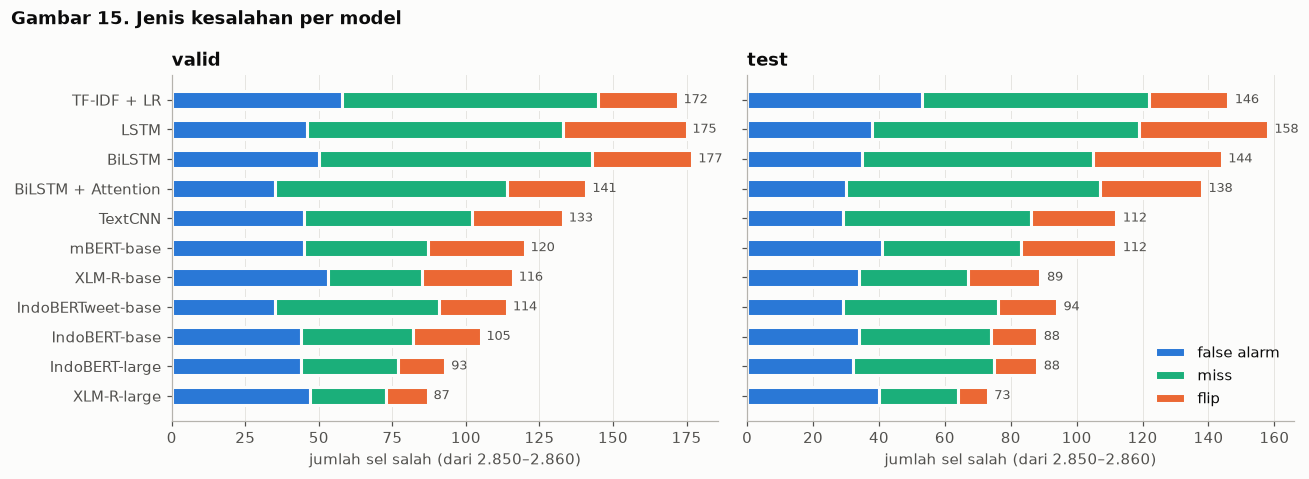

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, s in zip(axes, ["valid", "test"]):
    d = et.loc[s].iloc[::-1]
    left = np.zeros(len(d))
    for col, c in [("false alarm", BLUE), ("miss", AQUA), ("flip", ORANGE)]:
        ax.barh(d.index, d[col], left=left, color=c, height=0.62, edgecolor=SURFACE, linewidth=2, label=col)
        left += d[col].to_numpy()
    for i, t in enumerate(d.total):
        ax.text(t + 2, i, str(t), va="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"{s}")
    ax.set_xlabel("jumlah sel salah (dari 2.850–2.860)")
    ax.grid(axis="y", visible=False)
axes[1].legend(loc="lower right")
fig.suptitle("Gambar 15. Jenis kesalahan per model", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "15_jenis_kesalahan.png")
plt.show()

Pada XLM-R-large, 64 dari 73 sel yang salah di test (88%) berupa *miss* atau *false alarm*, dan hanya 9 sel yang polaritasnya terbalik. Kesalahan transformer terutama terletak pada deteksi aspek, dengan *false alarm* (40) lebih banyak daripada *miss* (24). Model yang lebih lemah lebih sering salah polaritas; LSTM dan BiLSTM masing-masing membuat 39 *flip*, sedangkan transformer large hanya 9–13. Pola yang sama terlihat pada valid (Gambar 15, kiri). Dugaan pada notebook 1 bahwa kelas `pos` yang langka akan menjadi sumber kesalahan terbesar tidak terbukti, karena 131 dari 139 sel `pos` di test diprediksi benar.

### 2.2 Kesalahan per aspek

,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
jumlah neg (test),45,38,41,5,96,80,43,14,26,35
jumlah neut (test),233,245,244,243,158,197,207,264,257,250
jumlah pos (test),8,3,1,38,32,9,36,8,3,1


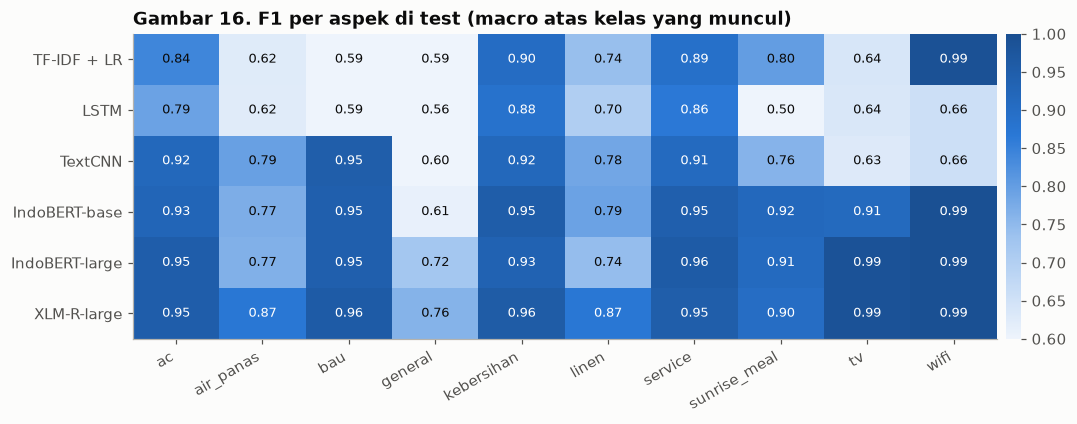

Jumlah sel salah XLM-R-large per aspek:


,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
valid,3,6,6,13,24,16,9,3,5,2
test,3,4,9,13,12,14,10,5,2,1


In [5]:
def f1_aspect(y, p):
    out = {}
    for j, a in enumerate(ASPECTS):
        labels = sorted(set(y[:, j]) | set(p[:, j]))
        out[a] = f1_score(y[:, j], p[:, j], labels=labels, average="macro")
    return out


SHOW = ["TF-IDF + LR", "LSTM", "TextCNN", "IndoBERT-base", "IndoBERT-large", "XLM-R-large"]
pa = pd.DataFrame({m: f1_aspect(Y["test"], pred(m, "test")) for m in SHOW}).T
support = pd.DataFrame({c: (Y["test"] == i).sum(0) for i, c in enumerate(CL)}, index=ASPECTS).T
display(support.rename(index=lambda c: f"jumlah {c} (test)"))

cmap = LinearSegmentedColormap.from_list("biru", ["#eef4fc", "#9ec3ef", BLUE, "#1a4f91"])
fig, ax = plt.subplots(figsize=(10.5, 3.6))
im = ax.imshow(pa.to_numpy(), cmap=cmap, vmin=0.6, vmax=1.0, aspect="auto")
for i in range(pa.shape[0]):
    for j in range(pa.shape[1]):
        v = pa.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > 0.85 else INK)
ax.set_xticks(range(len(ASPECTS)), ASPECTS, rotation=30, ha="right")
ax.set_yticks(range(len(SHOW)), SHOW)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).outline.set_visible(False)
ax.set_title("Gambar 16. F1 per aspek di test (macro atas kelas yang muncul)")
fig.savefig(FIG_DIR / "16_f1_per_aspek.png")
plt.show()

err_aspect = pd.DataFrame({s: (pred(BEST, s) != Y[s]).sum(0) for s in ["valid", "test"]}, index=ASPECTS)
print("Jumlah sel salah XLM-R-large per aspek:")
display(err_aspect.T)

Aspek `general` paling sulit bagi semua model, karena mewakili kesan keseluruhan tanpa kata kunci tetap dan hanya memiliki 5 contoh `neg` di test. Kesalahan absolut terbanyak terdapat pada `kebersihan`, `linen`, dan `general`. Batas `kebersihan` dan `linen` tumpang tindih dengan `bau`, misalnya pada *kasur kotor*, *sprei bau*, dan *handuk apek*. Aspek dengan kata kunci jelas (`ac`, `wifi`, `tv`) hampir selalu benar. F1 aspek yang hanya memiliki 1–3 sel `pos` di test dapat berubah tajam karena satu sel.

### 2.3 Karakteristik ulasan yang sulit

Tabel berikut membandingkan persentase ulasan dengan minimal satu sel salah pada XLM-R-large, antara ulasan dengan dan tanpa ciri tertentu.

In [6]:
def review_features(d, y):
    txt = d.review.str.lower()
    n_words = d.review.str.split().str.len()
    return {
        "panjang > median": (n_words > n_words.median()).to_numpy(),
        "membahas ≥ 3 aspek": ((y != 1).sum(1) >= 3),
        "ada kata kontras (tapi, namun, cuma, sayang, ...)": txt.str.contains(r"\b(?:tapi|tp|tpi|tetapi|namun|cuma|cm|cuman|sayang|sayangnya|hanya)\b").to_numpy(),
        "ada negasi (tidak, gak, kurang, belum, ...)": txt.str.contains(r"\b(?:tidak|tdk|gak|ga|gk|nggak|ngga|enggak|kurang|blm|belum|bukan)\b").to_numpy(),
        "ditandai `suspect` (notebook 1)": (d.suspect != "").to_numpy(),
    }


rows = []
for s in ["valid", "test"]:
    wrong = (pred(BEST, s) != Y[s]).any(1)
    for k, m in review_features(DATA[s], Y[s]).items():
        rows.append({"split": s, "ciri ulasan": k, "n": int(m.sum()), "% ulasan salah (dengan ciri)": 100 * wrong[m].mean(),
                     "% ulasan salah (tanpa ciri)": 100 * wrong[~m].mean()})
pd.DataFrame(rows).set_index(["ciri ulasan", "split"]).sort_index(level=0, sort_remaining=False).round(1)

n  % ulasan salah (dengan ciri)  % ulasan salah (tanpa ciri)
ciri ulasan                                       split                                                                
ada kata kontras (tapi, namun, cuma, sayang, ...) valid  120                          29.2                         19.4
                                                  test   119                          25.2                         17.4
ada negasi (tidak, gak, kurang, belum, ...)       valid  200                          26.0                         17.6
                                                  test   208                          17.8                         28.2
ditandai `suspect` (notebook 1)                   valid   43                          72.1                         14.9
                                                  test    34                          64.7                         14.7
membahas ≥ 3 aspek                                valid   78                          37.2                         18.4
                                                  test    70                          38.6                         14.8
panjang > median                                  valid  141                          31.9                         15.3
                                                  test   142                          27.5                         13.9

Ulasan yang lebih panjang dari median dan ulasan dengan tiga aspek atau lebih sekitar dua kali lebih sering salah, baik di valid maupun test, karena makin banyak keputusan yang harus diambil. Kata kontras (*tapi, namun, cuma*) menaikkan kesalahan sekitar 8–10 poin persentase, sedangkan pengaruh negasi tidak konsisten antara valid dan test.

Ulasan yang ditandai `suspect` pada notebook 1 bagian 6 salah pada 65–72% kasus, dibandingkan sekitar 15% untuk ulasan lain. Penanda ini dibuat sebelum ada model, yaitu ketika kata kunci aspek dan kata opini muncul tetapi aspeknya berlabel `neut`. Angka ini mengindikasikan bahwa sebagian kesalahan berasal dari label.

### 2.4 Keyakinan model ketika salah

In [7]:
p = probs(BEST, "test")
conf = p.max(-1).ravel()
correct = (p.argmax(-1) == Y["test"]).ravel()
bins = [0, 0.6, 0.8, 0.95, 1.0001]
cal = pd.DataFrame({"rentang keyakinan": pd.cut(conf, bins, right=False), "benar": correct}).groupby("rentang keyakinan", observed=True).benar
cal = pd.DataFrame({"jumlah sel": cal.size(), "akurasi": cal.mean().round(3), "jumlah salah": cal.size() - cal.sum()})
cal

,jumlah sel,akurasi,jumlah salah
rentang keyakinan,,,
"[0.0, 0.6)",27,0.481,14
"[0.6, 0.8)",57,0.754,14
"[0.8, 0.95)",134,0.858,19
"[0.95, 1.0)",2642,0.990,26


Sebanyak 92% sel diprediksi dengan keyakinan minimal 0,95 dan akurasinya 99%, sehingga model terkalibrasi cukup baik. Meskipun demikian, 26 dari 73 kesalahan terjadi pada keyakinan setinggi itu. Kesalahan seperti ini tidak dapat diperbaiki dengan menggeser ambang keputusan.

### 2.5 Kesalahan sistematis dan kesalahan acak

Sel yang salah diprediksi oleh kelima transformer, padahal arsitektur dan data pretraining-nya berbeda, kemungkinan besar disebabkan oleh data. Untuk setiap sel test dihitung jumlah transformer yang salah memprediksinya.

In [8]:
wrong_k = np.stack([pred(m, "test") != Y["test"] for m in TRANSFORMERS]).sum(0)
dist = pd.Series({k: int((wrong_k == k).sum()) for k in range(1, 6)}, name="jumlah sel")
dist.index.name = "salah oleh k dari 5 transformer"
display(dist.to_frame().T)
best_wrong = pred(BEST, "test") != Y["test"]
print(f"Kesalahan XLM-R-large: {best_wrong.sum()} sel; {(best_wrong & (wrong_k == 5)).sum()} di antaranya juga salah di "
      f"keempat transformer lain ({100 * (best_wrong & (wrong_k == 5)).sum() / best_wrong.sum():.0f}%)")

salah oleh k dari 5 transformer,1,2,3,4,5
jumlah sel,42,27,18,13,46


Kesalahan XLM-R-large: 73 sel; 46 di antaranya juga salah di keempat transformer lain (63%)


Sebanyak 46 dari 73 kesalahan XLM-R-large (63%) juga dibuat oleh keempat transformer lainnya. Kesalahan ini tidak akan hilang dengan mengganti atau menggabungkan model, sehingga ke-46 sel tersebut diperiksa satu per satu pada bagian 3.

## 3. Penyebab Kesalahan

Ke-46 sel yang salah pada kelima transformer dibaca satu per satu dan dikelompokkan ke dalam empat kategori.

| Kategori | Arti |
|---|---|
| Label noise | teks jelas bertentangan dengan label emas, dan prediksi model lebih masuk akal |
| Batas aspek | opini nyata, tetapi anotator memasukkannya ke aspek lain dengan konvensi yang tidak tertulis |
| Aspek implisit | aspek dinilai tanpa kata kunci |
| Kesalahan model | label wajar dan teks jelas bagi manusia, tetapi model gagal |

Pengelompokan ini merupakan penilaian manual penulis, sehingga setiap sel disertai teks ulasan dan alasannya agar dapat diperiksa kembali.

In [9]:
ANNOT = [  # (indeks ulasan test, aspek, kategori, alasan)
    (55, "sunrise_meal", "label noise", "'tetap saja di buatkan sarapan' bernada positif, label neg"),
    (57, "service", "label noise", "'pihak hotel dg cepat merespon' positif, label neut"),
    (67, "bau", "label noise", "'bau kamar mandi sampai keluar', 'sprei bau badan', label neut"),
    (113, "service", "label noise", "'mohon di tingkatkan pelayanannya' negatif, label pos"),
    (126, "general", "label noise", "'untuk keseluruhan ok lah', label neut"),
    (152, "sunrise_meal", "label noise", "'makan paginya terlalu sedikit', label neut"),
    (153, "kebersihan", "label noise", "'bersih', label neut"),
    (165, "kebersihan", "label noise", "'kamar juga bersih', label neut"),
    (180, "air_panas", "label noise", "ulasan tidak menyebut air panas sama sekali, label neg"),
    (180, "wifi", "label noise", "'WiFi di atas gak ada', label neut (tampak tertukar dengan air_panas)"),
    (187, "bau", "label noise", "'Ac nya bau cuka', label neut"),
    (189, "air_panas", "label noise", "'ada air panas' disebut sebagai kelebihan, label neg"),
    (189, "linen", "label noise", "'sarung bantal kusam', 'selimut tipis', label pos"),
    (190, "general", "label noise", "'over all very2 good', label neut"),
    (222, "ac", "label noise", "'ac dingin' disebut sebagai kelebihan, label neg"),
    (246, "tv", "label noise", "'yg kurang cuma chanel tv', label neut"),
    (275, "service", "label noise", "'servicenya jelek banget', label neut"),
    (57, "tv", "batas aspek", "'colokan tv tidak ada' dianggap perlengkapan kamar, bukan tv"),
    (106, "linen", "batas aspek", "'aminities lengkap' termasuk linen menurut konvensi"),
    (119, "linen", "batas aspek", "'makanan kecil' (snack) termasuk linen menurut konvensi"),
    (139, "kebersihan", "batas aspek", "keluhan prosedur pembersihan kamar, bukan kondisi kebersihan"),
    (151, "ac", "batas aspek", "'aroma Ac' dihitung sebagai bau, bukan ac"),
    (157, "linen", "batas aspek", "'kasur kotor' termasuk linen menurut konvensi"),
    (162, "bau", "batas aspek", "'kamar pengap' tidak dihitung sebagai bau"),
    (196, "linen", "batas aspek", "'tempat penampung sampah' termasuk linen (amenities)"),
    (200, "kebersihan", "batas aspek", "'kasur ada kutu' dihitung kebersihan, bukan linen"),
    (230, "bau", "batas aspek", "'selimut dan bantal bau' dihitung bau ..."),
    (230, "linen", "batas aspek", "... dan tidak dihitung linen"),
    (246, "sunrise_meal", "batas aspek", "'snack' dihitung sarapan di sini, padahal di ulasan lain dihitung linen"),
    (255, "linen", "batas aspek", "'handuk berbau apek' tidak dihitung linen"),
    (265, "linen", "batas aspek", "'fasilitas keren' termasuk linen menurut konvensi"),
    (272, "kebersihan", "batas aspek", "'kebersihan kasurnya' dihitung linen, bukan kebersihan"),
    (282, "bau", "batas aspek", "'sprei lembab jd bau' dihitung linen, bukan bau"),
    (43, "service", "aspek implisit", "masalah pemesanan 2 kamar dihitung service tanpa kata 'pelayanan'"),
    (50, "service", "aspek implisit", "'kamar hanya satu kali dibersihkan' dihitung service"),
    (75, "general", "aspek implisit", "'pelayanan dan kenyamanan oke' dihitung general"),
    (159, "general", "aspek implisit", "'lbh parah dr kost2an' sebagai penilaian keseluruhan"),
    (162, "general", "aspek implisit", "'sisanya okay' tidak dihitung general"),
    (166, "service", "aspek implisit", "'sedikit kurang friendly' tanpa subjek"),
    (209, "general", "aspek implisit", "'nggak recommended, mending cari yg lain'"),
    (255, "general", "aspek implisit", "'menurut saya mengecewakan'"),
    (76, "air_panas", "kesalahan model", "slang 'air panesnya jengkelin'"),
    (80, "kebersihan", "kesalahan model", "sarkasme 'bersahabat dengan NYAMUK'"),
    (100, "linen", "kesalahan model", "'handuk kasih double' positif; model terbawa 'ac kurang dingin'"),
    (136, "air_panas", "kesalahan model", "pragmatik 'akhirnya air panasnya ada juga hahaha'"),
    (205, "sunrise_meal", "kesalahan model", "pujian lemah 'makanan seadanya, cukuplah buat sarapan'"),
]
ann = pd.DataFrame(ANNOT, columns=["i", "aspek", "kategori", "alasan"])
hard = {(i, ASPECTS[j]) for i, j in zip(*np.where(wrong_k == 5))}
assert hard == set(zip(ann.i, ann.aspek)), "anotasi tidak cocok dengan sel yang salah di kelima transformer"

pb = probs(BEST, "test")
ann["label"] = [CL[Y["test"][i, ASPECTS.index(a)]] for i, a in zip(ann.i, ann.aspek)]
ann["prediksi"] = [CL[pb[i, ASPECTS.index(a)].argmax()] for i, a in zip(ann.i, ann.aspek)]
ann["keyakinan"] = [pb[i, ASPECTS.index(a)].max().round(2) for i, a in zip(ann.i, ann.aspek)]
ann["ulasan"] = [DATA["test"].review[i] for i in ann.i]
display(ann.kategori.value_counts().to_frame("jumlah sel"))

,jumlah sel
kategori,
label noise,17
batas aspek,16
aspek implisit,8
kesalahan model,5


In [10]:
for kat, g in ann.groupby("kategori", sort=False):
    print(f"\n=== {kat} ({len(g)} sel) ===")
    display(g[["i", "aspek", "label", "prediksi", "keyakinan", "alasan", "ulasan"]].reset_index(drop=True))


=== label noise (17 sel) ===


,i,aspek,label,prediksi,keyakinan,alasan,ulasan
0,55,sunrise_meal,neg,pos,0.64,"'tetap saja di buatkan sarapan' bernada positif, label neg","tempat memang tidak strategis. bangunannya pun sudah usang dan tidak terurus karena hotelnya sangat sepi. beberapa fasilitas hotel pun ada yang rusak, conto..."
1,57,service,neut,pos,0.36,"'pihak hotel dg cepat merespon' positif, label neut","awalnya sudah merasa tidak nyaman karena lantai kamar agak berdebu. setelah masuk, cek handuk & keset serta tempat sampah tidak disediakan, sambungan coloka..."
2,67,bau,neut,neg,0.95,"'bau kamar mandi sampai keluar', 'sprei bau badan', label neut","kecewa sangat sangat kecewa.. kamarnya sangat kotor, bau kamar mandi sampai keluar, sprei bau badan, pdhl baru msuk kamar 3 jam.. sudah lapor ke service tp ..."
3,113,service,pos,neg,0.90,"'mohon di tingkatkan pelayanannya' negatif, label pos","Saya menginap 3 malam, tetapi snak, air minum dan perlengkapan mandi tdk di lengkapi ulang/tdk di kasih ke tamu.. mohon di tingkatkan pelayanannya.. terimak..."
4,126,general,neut,pos,1.00,"'untuk keseluruhan ok lah', label neut",nyaman tempatnya cuman sayang air panas nya tdk bisa. untuk keseluruhan ok lah.
5,152,sunrise_meal,neut,neg,0.99,"'makan paginya terlalu sedikit', label neut","air panasnya mati,makan paginya terlalu sedikit"
6,153,kebersihan,neut,pos,0.99,"'bersih', label neut","Kamarnya nyaman, pelayanan baik, bersih, hanya saja bantal sedikit bau"
7,165,kebersihan,neut,pos,0.97,"'kamar juga bersih', label neut","Receptionist hotel sangat ramah, kamar juga bersih luas dan dikasih snack ringan tiap hari. Cuma kemarin air panas di kamar mandi kurang berfungsi"
8,180,air_panas,neg,neut,0.98,"ulasan tidak menyebut air panas sama sekali, label neg","tempat bersih, rapi, nyaman, sesuai harga lah pokoknya, cuman WiFi di atas gak ada jd mau WiFian harus ke bawah, overall good👌"
9,180,wifi,neut,neg,0.98,"'WiFi di atas gak ada', label neut (tampak tertukar dengan air_panas)","tempat bersih, rapi, nyaman, sesuai harga lah pokoknya, cuman WiFi di atas gak ada jd mau WiFian harus ke bawah, overall good👌"



=== batas aspek (16 sel) ===


,i,aspek,label,prediksi,keyakinan,alasan,ulasan
0,57,tv,neut,neg,0.97,"'colokan tv tidak ada' dianggap perlengkapan kamar, bukan tv","awalnya sudah merasa tidak nyaman karena lantai kamar agak berdebu. setelah masuk, cek handuk & keset serta tempat sampah tidak disediakan, sambungan coloka..."
1,106,linen,pos,neut,0.83,'aminities lengkap' termasuk linen menurut konvensi,"Kamarnya bersih, aminities lengkap, petugas ramah. Cm km mandi agak bau. Yg lain bagus buat harga semurah itu."
2,119,linen,neg,neut,0.73,'makanan kecil' (snack) termasuk linen menurut konvensi,g ada makann kecil y
3,139,kebersihan,neut,neg,0.64,"keluhan prosedur pembersihan kamar, bukan kondisi kebersihan","ruangan lebar. namun kekurangannya tidak ada hot shower. kamar dibersihkan tanpa diminta, tetapi hal tersebut sangat berbahaya untuk menjaga kepercayaan pel..."
4,151,ac,neut,neg,0.99,"'aroma Ac' dihitung sebagai bau, bukan ac",lebih membutuhkan maintenance untuk kamar mandi dan aroma Ac/kamarnya
5,157,linen,neg,neut,0.51,'kasur kotor' termasuk linen menurut konvensi,mayan lah deket farm house cuman kamar mandi kotor kasur kotor
6,162,bau,neut,neg,0.93,'kamar pengap' tidak dihitung sebagai bau,"kamar pengap, properti seperti meja terasa kurang bersih. sisanya okay"
7,196,linen,neg,neut,0.74,'tempat penampung sampah' termasuk linen (amenities),"Gak nyaman banget, krna Ac nya rusak, gak dingin trs suka mati sndiri dlm beberapa wktu, trs airnya gak mengalir dgn lancar suka ngadat. Kebersihan msh oke..."
8,200,kebersihan,neg,neut,0.55,"'kasur ada kutu' dihitung kebersihan, bukan linen","Kasur ada kutu nya, dan badan saya jadi gatal gatal.. Dan ac sama sekali tdk dingin"
9,230,bau,neg,neut,0.79,'selimut dan bantal bau' dihitung bau ...,"Selimut dan bantal bau seperti belum dicuci, masih ada rambut bertebaran di bantal"



=== aspek implisit (8 sel) ===


,i,aspek,label,prediksi,keyakinan,alasan,ulasan
0,43,service,neg,neut,1.00,masalah pemesanan 2 kamar dihitung service tanpa kata 'pelayanan',"parah... pesan 2 kamar, 1 kamarnya tidak ada perlengkapan airy belum di siapkan, karena tidak terdetect kalau pesan 2 kamar... kamar bau apek... not recomen..."
1,50,service,neg,neut,0.96,'kamar hanya satu kali dibersihkan' dihitung service,"saya menginap di kamar 117, reviewnya: 1. bantal keras 2. biasanya dikasih bantal airy, tapi ini ga ada. dikasih dua bantal tambahan sih tapi ga dikasih sar..."
2,75,general,pos,neut,1.00,'pelayanan dan kenyamanan oke' dihitung general,"untuk pelayanan dan kenyamanan oke, cuma lantai di kamarnya agak sedikit kotor seperti tidak di pel"
3,159,general,neg,neut,0.97,'lbh parah dr kost2an' sebagai penilaian keseluruhan,"staff hotel tidak peduli kepada keluhan customer, token listrik bunyi dibiarkan dan bunyi nya sangat mengganggu, saya hrus 2 jam skali bangun buat mematikan..."
4,162,general,neut,pos,0.98,'sisanya okay' tidak dihitung general,"kamar pengap, properti seperti meja terasa kurang bersih. sisanya okay"
5,166,service,neg,neut,0.69,'sedikit kurang friendly' tanpa subjek,"kamarnya nyaman tp di lantai2 ga kena wifi, dan sedikit kurang friendly. breakfastnya enak. yang double recommeded kalo ada wifinya"
6,209,general,neg,neut,0.96,"'nggak recommended, mending cari yg lain'","utk kamar disini nggak recommended, mending cari yg lain...nginep 2 malam dpt kamar L lantai 3 kamarnya jelek...pintu kamar mandi engsel atas lepas, jd pint..."
7,255,general,neg,neut,0.95,'menurut saya mengecewakan',"Kamar mandi lembab, exhaust/vacuum di kamar mandi tidak berfungsi sehingga handuk dan kain lainnya berbau apek. Pelayanan ramah Sarapannya tidak enak Keber..."



=== kesalahan model (5 sel) ===


,i,aspek,label,prediksi,keyakinan,alasan,ulasan
0,76,air_panas,neg,neut,0.99,slang 'air panesnya jengkelin',luas bgt..tp air panesnya jengkelin
1,80,kebersihan,neg,neut,0.96,sarkasme 'bersahabat dengan NYAMUK',"Hotel yang bersahabat dengan NYAMUK, makanan selalu HABIS"
2,100,linen,pos,neg,0.97,'handuk kasih double' positif; model terbawa 'ac kurang dingin',"handuk kasih double, ac kurang dingin, semoga lebih baik lagi"
3,136,air_panas,pos,neg,1.00,pragmatik 'akhirnya air panasnya ada juga hahaha',4x menginap disini akhir nya air panas nya ada juga hahahahhaa
4,205,sunrise_meal,neg,pos,0.73,"pujian lemah 'makanan seadanya, cukuplah buat sarapan'","pelayanan baik banget dan ramah, makanan seadanya, cukuplah buat sarapan, sprei kurang bersih, pintu kamar mandi ga bisa ditutup. sebrangnya ada kupat tahu,..."


In [11]:
y_fix = Y["test"].copy()
p_best = pred(BEST, "test")
for i, a in ann.loc[ann.kategori == "label noise", ["i", "aspek"]].itertuples(index=False):
    y_fix[i, ASPECTS.index(a)] = p_best[i, ASPECTS.index(a)]
print(f"F1 test XLM-R-large: {f1_indonlu(Y['test'], p_best):.4f}; jika {(ann.kategori == 'label noise').sum()} sel "
      f"label noise dianggap benar: {f1_indonlu(y_fix, p_best):.4f}")

F1 test XLM-R-large: 0.9454; jika 17 sel label noise dianggap benar: 0.9631


Hanya 5 dari 46 sel (11%) yang merupakan kesalahan model, yaitu slang, sarkasme, dan ungkapan pragmatik. Sisanya berasal dari data. Jika 17 sel label noise dianggap benar, F1 test XLM-R-large naik dari 0,9454 menjadi 0,9631; angka ini memberi gambaran kasar batas atas pada test ini. Pada 16 sel batas aspek, anotator memasukkan kasur, sprei, handuk, snack, dan amenities ke `linen`, tetapi tidak selalu konsisten. Snack dihitung sebagai `linen` pada satu ulasan dan sebagai `sunrise_meal` pada ulasan lain. Delapan sel sisanya adalah aspek implisit, terutama `general` dan `service`.

Label test tidak boleh diubah agar hasil tetap sebanding dengan penelitian lain. Perbaikan karena itu diarahkan pada pengajaran konvensi batas aspek kepada model dan pengurangan 27 kesalahan acak.

### 3.1 Ringkasan letak, penyebab, dan cara mengatasi kesalahan

| Letak | Besarnya (XLM-R-large, test) | Penyebab | Cara mengatasi | Hasil |
|---|---|---|---|---|
| Deteksi aspek | 64 dari 73 sel salah | batas aspek tidak tercermin pada nama aspek, aspek implisit, label noise | AspAttn-Desc (5.2), ensemble (4, 6) | +1,16 poin pada IndoBERT-base; ensemble dipakai pada model akhir |
| Polaritas (*flip*) | 9 sel; BiLSTM 39 sel | negasi, kontras, slang, sarkasme | pretraining Transformer | *flip* turun dari 39 menjadi 9; slang dan sarkasme belum teratasi |
| Aspek `general` | F1 per aspek terendah | kesan keseluruhan tanpa kata kunci | query deskripsi berisi *overall, keseluruhan* (5.2) | membantu model base |
| `kebersihan`, `linen`, `bau` | kesalahan absolut terbanyak | konvensi anotator yang tumpang tindih | AspAttn-Desc; saran: pedoman anotasi tertulis | hanya 2–6 dari 46 sel sistematis diperbaiki (5.4) |
| Ulasan panjang, ≥ 3 aspek | sekitar 2 kali lebih sering salah | lebih banyak keputusan per ulasan | attention per aspek (5.2) | ikut membaik |
| Label noise | 17 sel, sekitar 1,8 poin F1 | label emas keliru | label test tidak diubah; label smoothing (5.1), *confident learning* (5.5); saran: anotasi ulang | tidak membantu |
| Salah dengan keyakinan tinggi | 26 dari 73 kesalahan | label dan konvensi | geser ambang `neut` per aspek (4) | overfit ke valid, ditolak |

Model masih dapat mengurangi kesalahan acak dan sebagian kesalahan deteksi aspek. Kesalahan sistematis lainnya memerlukan perbaikan data.

## 4. Mitigasi tanpa Pelatihan Ulang

Tiga cara berikut hanya memakai probabilitas yang sudah tersimpan.
1. Rata-rata probabilitas tiga seed dari model yang sama.
2. Ensemble antarmodel, dengan model dipilih berdasarkan F1 valid.
3. Bias kelas `neut` per aspek, karena *false alarm* lebih banyak daripada *miss*. Besar bias dicari pada valid (grid −2 sampai 2).

In [12]:
def show(rows):
    return pd.DataFrame(rows).set_index("cara").style.format("{:.4f}")


base_rows = [{"cara": "XLM-R-large, rata-rata F1 per seed", "F1 valid": seed_mean(BEST, "valid"), "F1 test": seed_mean(BEST, "test")},
             {"cara": "XLM-R-large, rata-rata probabilitas 3 seed", "F1 valid": f1_indonlu(Y["valid"], pred(BEST, "valid")),
              "F1 test": f1_indonlu(Y["test"], pred(BEST, "test"))}]

ranked = sorted(LADDER[1:], key=lambda m: -f1_indonlu(Y["valid"], pred(m, "valid")))
for k in [2, 3, 4, 5]:
    pv = np.mean([probs(m, "valid") for m in ranked[:k]], 0)
    pt = np.mean([probs(m, "test") for m in ranked[:k]], 0)
    base_rows.append({"cara": f"ensemble top-{k} valid: {', '.join(ranked[:k])}",
                      "F1 valid": f1_indonlu(Y["valid"], pv.argmax(-1)), "F1 test": f1_indonlu(Y["test"], pt.argmax(-1))})


def tune_neut_bias(pv, y, grid=np.linspace(-2, 2, 21), rounds=2):
    b = np.zeros(len(ASPECTS))
    lv = np.log(pv + 1e-9)
    for _ in range(rounds):
        for j in range(len(ASPECTS)):
            def score(g):
                bb = b.copy()
                bb[j] = g
                return f1_indonlu(y, (lv + bb[:, None] * np.eye(3)[1]).argmax(-1)), -abs(g)
            b[j] = max(grid, key=score)
    return b


bias = tune_neut_bias(probs(BEST, "valid"), Y["valid"])
apply_bias = lambda p: (np.log(p + 1e-9) + bias[:, None] * np.eye(3)[1]).argmax(-1)
base_rows.append({"cara": "XLM-R-large + bias neut per aspek (dicari di valid)",
                  "F1 valid": f1_indonlu(Y["valid"], apply_bias(probs(BEST, "valid"))),
                  "F1 test": f1_indonlu(Y["test"], apply_bias(probs(BEST, "test")))})
display(show(base_rows))
print("Bias neut per aspek:", dict(zip(ASPECTS, bias.round(1))))

,F1 valid,F1 test
cara,,
"XLM-R-large, rata-rata F1 per seed",0.9279,0.9423
"XLM-R-large, rata-rata probabilitas 3 seed",0.9274,0.9454
"ensemble top-2 valid: XLM-R-large, IndoBERT-large",0.9325,0.9463
"ensemble top-3 valid: XLM-R-large, IndoBERT-large, IndoBERT-base",0.9267,0.9411
"ensemble top-4 valid: XLM-R-large, IndoBERT-large, IndoBERT-base, IndoBERTweet-base",0.9200,0.9396
"ensemble top-5 valid: XLM-R-large, IndoBERT-large, IndoBERT-base, IndoBERTweet-base, XLM-R-base",0.9161,0.9354
XLM-R-large + bias neut per aspek (dicari di valid),0.9361,0.9370


Bias neut per aspek: {'ac': np.float64(0.0), 'air_panas': np.float64(-0.6), 'bau': np.float64(0.6), 'general': np.float64(1.2), 'kebersihan': np.float64(0.4), 'linen': np.float64(0.6), 'service': np.float64(0.0), 'sunrise_meal': np.float64(0.0), 'tv': np.float64(1.8), 'wifi': np.float64(-0.2)}


Perata-rataan seed menaikkan F1 test XLM-R-large dari 0,9423 menjadi 0,9454 tanpa biaya tambahan. Ensemble dua model teratas menurut valid (XLM-R-large dan IndoBERT-large) memberi F1 valid 0,9325 dan F1 test 0,9463, sedangkan menambahkan model yang lebih lemah menurunkan skor. Bias `neut` per aspek menaikkan valid menjadi 0,9361 tetapi menurunkan test menjadi 0,9370. Sepuluh parameter yang dicari pada 285 ulasan valid membuat cara ini overfit, sehingga ditolak.

## 5. Mitigasi dengan Pelatihan Ulang

Semua varian dikembangkan pada IndoBERT-base (sekitar 2,5 menit per run) dengan protokol notebook 2, yaitu tiga seed dan epoch terbaik menurut valid. Varian hanya dibawa ke model large apabila lebih baik di valid.

### 5.1 Label smoothing

Label smoothing (ε = 0,1) merupakan cara umum untuk melatih model pada label yang tidak sepenuhnya benar. Hasilnya ditampilkan bersama varian lain pada akhir bagian 5.2.

### 5.2 Pendekatan baru: AspAttn-Desc

Bagian 3 menunjukkan bahwa sebagian besar kesalahan sistematis berkaitan dengan penentuan aspek yang dibahas, dan anotator memakai konvensi yang tidak tercermin pada nama aspek, misalnya `linen` mencakup snack dan air minum. Model baseline merangkum seluruh ulasan menjadi satu vektor `[CLS]` yang dibaca oleh sepuluh classifier. Attention per aspek dipakai agar setiap aspek dapat membaca bagian ulasan yang berbeda. Untuk state encoder $H \in \mathbb{R}^{T \times d}$, setiap aspek $a$ memiliki query $q_a \in \mathbb{R}^d$:

$$\alpha_a = \mathrm{softmax}\!\left(\frac{H q_a}{\sqrt{d}}\right), \qquad z_a = \left[\,\alpha_a^\top H \;;\; h_{\texttt{[CLS]}}\,\right], \qquad \text{logit}_a = W_a z_a + b_a$$

Kebaruannya terletak pada inisialisasi query. Vektor $q_a$ diisi dengan representasi encoder atas deskripsi aspek. Deskripsi dibentuk otomatis dari data train, berupa nama aspek ditambah delapan kata yang paling berasosiasi dengan aspek tersebut menurut uji chi-kuadrat. Dengan cara ini, konvensi anotator masuk ke model tanpa aturan buatan tangan dan tanpa melihat valid atau test.

Attention per aspek sudah dikenal dalam ABSA (ATAE-LSTM, Wang dkk., 2016), dan embedding label sebagai query dipakai pada klasifikasi teks (LEAM, Wang dkk., 2018). Formulasi *auxiliary sentence* (Sun dkk., 2019) memasukkan nama aspek sebagai kalimat kedua, tetapi membutuhkan sepuluh *forward pass* per ulasan, sedangkan AspAttn-Desc cukup satu. Sebagai ablasi, AspAttn dengan query acak juga dilatih dengan learning rate head yang sama (1e-3).

Skema berikut merangkum alurnya, diikuti kode asli dari `src/hoasa/train.py` dan `src/hoasa/models.py`.

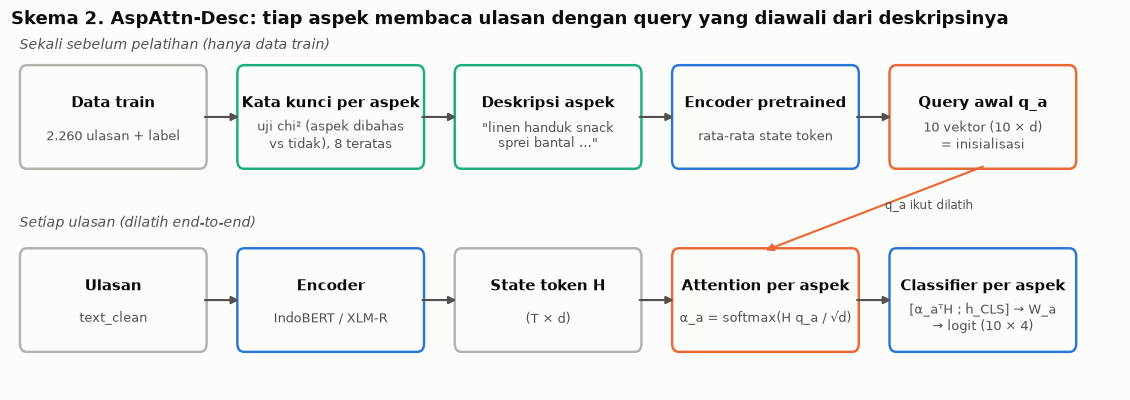

In [13]:
from matplotlib.patches import FancyBboxPatch


def box(ax, x, y, w, h, title, sub="", color=MUTED):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=SURFACE, ec=color, lw=1.6))
    ax.text(x, y + (0.13 if sub else 0), title, ha="center", va="center", fontsize=9.6, fontweight="bold", color=INK)
    if sub:
        ax.text(x, y - 0.17, sub, ha="center", va="center", fontsize=8.3, color=INK_2, linespacing=1.3)


def arrow(ax, x0, y0, x1, y1, color=INK_2):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, shrinkA=0, shrinkB=0))


fig, ax = plt.subplots(figsize=(13, 4.2))
ax.set_xlim(0, 13)
ax.set_ylim(0, 3.4)
ax.axis("off")
w, h, X = 2.15, 0.95, [1.2, 3.75, 6.3, 8.85, 11.4]
lanes = {2.6: [("Data train", "2.260 ulasan + label", MUTED), ("Kata kunci per aspek", "uji chi² (aspek dibahas\nvs tidak), 8 teratas", AQUA),
               ("Deskripsi aspek", "\"linen handuk snack\nsprei bantal …\"", AQUA), ("Encoder pretrained", "rata-rata state token", BLUE),
               ("Query awal q_a", "10 vektor (10 × d)\n= inisialisasi", ORANGE)],
         0.85: [("Ulasan", "text_clean", MUTED), ("Encoder", "IndoBERT / XLM-R", BLUE), ("State token H", "(T × d)", MUTED),
                ("Attention per aspek", "α_a = softmax(H q_a / √d)", ORANGE), ("Classifier per aspek", "[α_aᵀH ; h_CLS] → W_a\n→ logit (10 × 4)", BLUE)]}
for y, row in lanes.items():
    for x, (t, sub, c) in zip(X, row):
        box(ax, x, y, w, h, t, sub, c)
    for x0, x1 in zip(X, X[1:]):
        arrow(ax, x0 + w / 2, y, x1 - w / 2, y)
arrow(ax, X[4], 2.6 - h / 2, X[3], 0.85 + h / 2, color=ORANGE)
ax.text(10.25, 1.72, "q_a ikut dilatih", fontsize=8, color=INK_2)
ax.text(0.1, 3.25, "Sekali sebelum pelatihan (hanya data train)", fontsize=9, color=INK_2, fontstyle="italic")
ax.text(0.1, 1.55, "Setiap ulasan (dilatih end-to-end)", fontsize=9, color=INK_2, fontstyle="italic")
ax.set_title("Skema 2. AspAttn-Desc: tiap aspek membaca ulasan dengan query yang diawali dari deskripsinya")
fig.savefig(FIG_DIR / "skema_2_aspattn_desc.png")
plt.show()

In [14]:
from hoasa.models import TransformerAspect
from hoasa.train import aspect_descriptions, encode_descriptions

show_code(aspect_descriptions, encode_descriptions)

```python
def aspect_descriptions(train, k=8):
    """Deskripsi tiap aspek = nama aspek + k kata yang paling berasosiasi (chi2) dengan aspek itu dibahas di train.

    Hanya memakai data train, sehingga konvensi anotator (mis. snack/air minum masuk linen) dipelajari tanpa
    melihat valid/test. Kata yang sangat umum (muncul di >25% ulasan) dibuang.
    """
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.feature_selection import chi2

    cv = CountVectorizer(binary=True, min_df=5, max_df=0.25, token_pattern=r"(?u)\b[a-z]{3,}\b")
    X = cv.fit_transform(train["text_clean"].str.lower())
    vocab = cv.get_feature_names_out()
    out = {}
    for a in ASPECTS:
        y = (train[a] != "neut").to_numpy()
        score = np.where(np.asarray(X[y].mean(0) > X[~y].mean(0)).ravel(), chi2(X, y)[0], 0)
        top = [w for w in vocab[np.argsort(-score)] if w not in ASPECT_TEXT[a].split()][:k]
        out[a] = " ".join([ASPECT_TEXT[a]] + top)
    return out


@torch.no_grad()
def encode_descriptions(backbone, tok, desc):
    """Rata-rata state terakhir encoder atas token deskripsi (tanpa token spesial) -> (10, hidden)."""
    from transformers import AutoModel

    enc = AutoModel.from_pretrained(backbone).eval()
    t = tok([desc[a] for a in ASPECTS], padding=True, return_tensors="pt", return_special_tokens_mask=True)
    keep = (t.pop("special_tokens_mask") == 0) & (t["attention_mask"] == 1)
    h = enc(**t).last_hidden_state
    return (h * keep[..., None]).sum(1) / keep.sum(1, keepdim=True)
```

In [15]:
desc = next(r["cfg"]["desc"] for r in RUNS if r["name"] == "IndoBERT-base + AspAttn-Desc")   # tersimpan saat pelatihan
print("dihitung ulang dari train sama dengan yang dipakai saat pelatihan:", aspect_descriptions(load_processed("train")) == desc)
pd.Series(desc, name="deskripsi aspek (dari train)").to_frame()

dihitung ulang dari train sama dengan yang dipakai saat pelatihan: True


,deskripsi aspek (dari train)
ac,ac dingin acnya bocor berisik berasa gerah suhu nya
air_panas,air panas panasnya hangat hot berfungsi water shower heater hangatnya
bau,bau rokok pengap sedap berbau pengharum aroma wangi mandi
general,umum overall selebihnya all over keseluruhan oke lainnya semua
kebersihan,kebersihan bersih kotor banyak lantai mandi berdebu dibersihkan jorok
linen,linen snack handuk sprei bantal selimut airy perlengkapan minum
service,pelayanan ramah pelayanannya staff baik petugas jam tamu check
sunrise_meal,sarapan breakfast sarapannya enak menu makanan breakfastnya bervariasi nasi
tv,tv channel chanel siaran tvnya saluran remote jernih kabel
wifi,wifi wifinya sinyal connect lemot internet kenceng susah koneksi


Deskripsi hasil penambangan sesuai dengan temuan EDA. Deskripsi `linen` memuat *snack, handuk, sprei,* dan *minum*, sedangkan deskripsi `general` memuat *overall, selebihnya,* dan *keseluruhan*.

Dalam `TransformerAspect`, variabel `s` adalah skor $H q_a / \sqrt{d}$, `a` adalah $\alpha_a$, dan `z` adalah $[\alpha_a^\top H ; h_{\texttt{[CLS]}}]$. Classifier per aspek ditulis sebagai satu `einsum` dengan bobot `w` berukuran (10, 2d, 4).

In [16]:
show_code(TransformerAspect)

```python
class TransformerAspect(nn.Module):
    """Encoder pretrained + attention per aspek: tiap aspek punya vektor query sendiri yang memilih token relevan,
    lalu classifier per aspek di atas [vektor hasil attention; vektor token pertama].

    `query_init` (10, hidden) opsional, mis. representasi encoder atas deskripsi aspek; tanpa itu query diacak.
    """

    def __init__(self, name, query_init=None):
        from transformers import AutoModel
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        d = self.enc.config.hidden_size
        self.query = nn.Parameter(torch.randn(len(ASPECTS), d) * 0.02 if query_init is None else query_init.clone())
        self.drop = nn.Dropout(0.1)
        self.w = nn.Parameter(torch.empty(len(ASPECTS), 2 * d, N_CLS))
        self.b = nn.Parameter(torch.zeros(len(ASPECTS), N_CLS))
        for w in self.w:
            nn.init.xavier_uniform_(w)

    def forward(self, input_ids, attention_mask):
        h = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state   # (B, T, d)
        s = torch.einsum("btd,ad->bat", h, self.query) / h.shape[-1] ** 0.5
        a = s.masked_fill(attention_mask[:, None] == 0, -1e4).softmax(-1)                    # (B, 10, T)
        z = torch.cat([a @ h, h[:, :1].expand(-1, len(ASPECTS), -1)], -1)                    # (B, 10, 2d)
        return torch.einsum("bak,akc->bac", self.drop(z), self.w) + self.b
```

Gambar 17 menampilkan attention setiap aspek pada satu ulasan test sebelum pelatihan, dengan encoder IndoBERT-base pretrained dan query dari deskripsi. Kondisi ini merupakan titik awal AspAttn-Desc.

In [17]:
import warnings

import torch

warnings.filterwarnings("ignore", message="IProgress not found")
from huggingface_hub.utils import logging as hub_logging
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

BACKBONE = "indobenchmark/indobert-base-p1"
DEMO = 59                                                   # ulasan test yang juga dipakai sebagai demo di notebook 2
tok = AutoTokenizer.from_pretrained(BACKBONE)
torch.manual_seed(0)
model = TransformerAspect(BACKBONE, query_init=encode_descriptions(BACKBONE, tok, desc)).eval()
enc = tok(DATA["test"].text_clean[DEMO], return_tensors="pt")


def attention(query):
    # langkah attention dari TransformerAspect.forward untuk satu ulasan -> (10 aspek, T token)
    with torch.no_grad():
        h = model.enc(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state
        return torch.einsum("btd,ad->bat", h, query).div(h.shape[-1] ** 0.5).softmax(-1)[0].numpy()


att = attention(model.query)
att_rand = attention(torch.randn_like(model.query) * 0.02)  # inisialisasi AspAttn (query acak)
tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
print("ulasan:", DATA["test"].review[DEMO])
print(f"bobot attention maksimum per aspek, rata-rata: query deskripsi {att.max(1).mean():.2f} | query acak {att_rand.max(1).mean():.2f} "
      f"| seragam 1/T = {1 / len(tokens):.2f}")

ulasan: 4 hari inap tanpa snack, padahal standar nya airy selalu ada snack. handuk di hari 3 gak kebagian. kalo soal kebersihan gak ada masalah. cuma fasilitas nya aja yg kurang bisa dipenuhi.
bobot attention maksimum per aspek, rata-rata: query deskripsi 0.23 | query acak 0.03 | seragam 1/T = 0.03


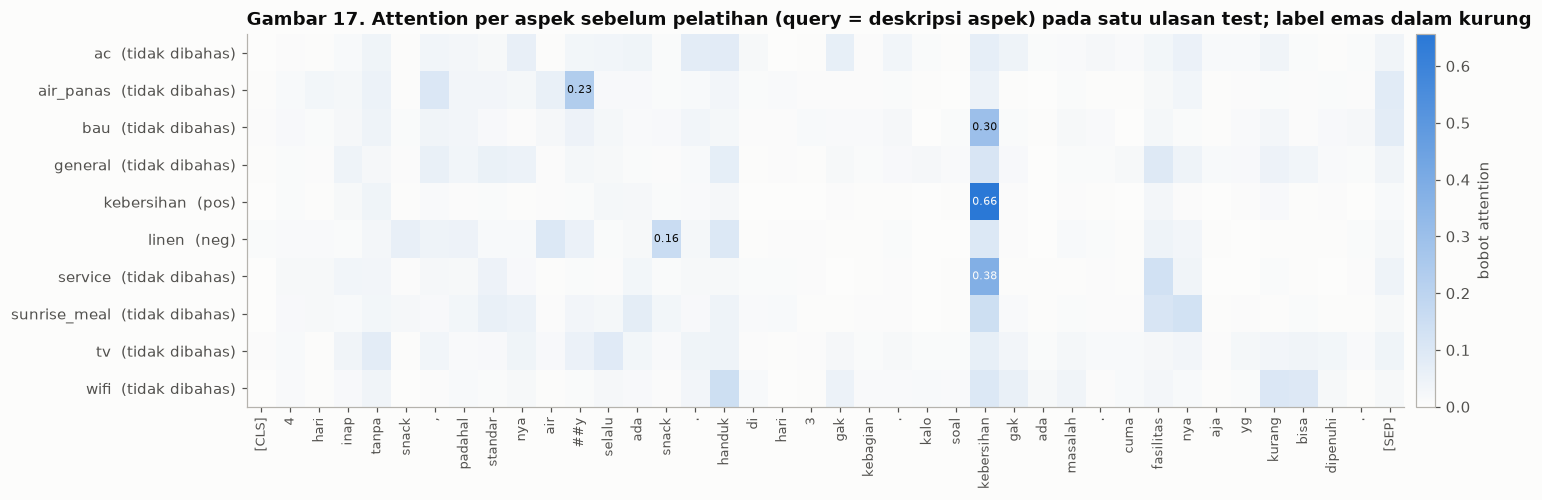

In [18]:
gold = DATA["test"].loc[DEMO, ASPECTS].replace({"neut": "tidak dibahas"})
fig, ax = plt.subplots(figsize=(14, 4.4))
im = ax.imshow(att, aspect="auto", cmap=LinearSegmentedColormap.from_list("biru", [SURFACE, BLUE]), vmin=0, vmax=att.max())
ax.set_xticks(range(len(tokens)), tokens, rotation=90, fontsize=8.5)
ax.set_yticks(range(len(ASPECTS)), [f"{a}  ({gold[a]})" for a in ASPECTS])
ax.grid(False)
for i, j in zip(*np.where(att >= 0.15)):
    ax.text(j, i, f"{att[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=SURFACE if att[i, j] > 0.35 else INK)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="bobot attention")
ax.set_title("Gambar 17. Attention per aspek sebelum pelatihan (query = deskripsi aspek) pada satu ulasan test; label emas dalam kurung")
fig.savefig(FIG_DIR / "17_attention_awal.png")
plt.show()

Tanpa pelatihan, query deskripsi sudah mengarah ke token yang tepat. Aspek `kebersihan` menempatkan sekitar dua pertiga bobotnya pada kata "kebersihan", dan bobot `linen` tersebar ke "snack" dan "handuk". Aspek yang tidak dibahas tidak menemukan token yang cocok, sehingga attention-nya menyebar. Titik awal ini belum sempurna, misalnya `air_panas` tertarik ke "air ##y" karena nama hotel Airy dipecah tokenizer menjadi "air". Dengan query acak, rata-rata bobot maksimum hanya 0,03, sama dengan bobot seragam, sedangkan query deskripsi menghasilkan 0,23.

In [19]:
VARIANTS = [("IndoBERT-base", "baseline ([CLS])"), ("IndoBERT-base + LS0.1", "label smoothing 0,1"),
            ("IndoBERT-base + AspAttn", "AspAttn (query acak)"), ("IndoBERT-base + AspAttn-Desc", "AspAttn-Desc")]
rows = []
for m, label in VARIANTS:
    v = [r["valid"]["f1_indonlu"] for r in RUNS if r["name"] == m]
    t = [r["test"]["f1_indonlu"] for r in RUNS if r["name"] == m]
    rows.append({"varian (IndoBERT-base)": label, "F1 valid": np.mean(v), "± sd valid": np.std(v, ddof=1),
                 "F1 test": np.mean(t), "± sd test": np.std(t, ddof=1),
                 "F1 pasangan test": seed_mean(m, "test", "f1_pair"), "exact match test": seed_mean(m, "test", "exact")})
pd.DataFrame(rows).set_index("varian (IndoBERT-base)").style.format("{:.4f}")

,F1 valid,± sd valid,F1 test,± sd test,F1 pasangan test,exact match test
varian (IndoBERT-base),,,,,,
baseline ([CLS]),0.9087,0.0088,0.9280,0.0064,0.9068,0.7517
"label smoothing 0,1",0.9060,0.0040,0.9275,0.0031,0.9064,0.7552
AspAttn (query acak),0.9011,0.0063,0.9183,0.0077,0.8956,0.7319
AspAttn-Desc,0.9294,0.0041,0.9338,0.0034,0.9121,0.7459


Label smoothing tidak berpengaruh (test 0,9275 dibandingkan baseline 0,9280), sehingga ditolak. AspAttn dengan query acak lebih buruk daripada baseline (test 0,9183), karena attention per aspek terlalu sulit dipelajari dari nol dengan 2.260 ulasan. AspAttn-Desc menaikkan F1 valid dari 0,909 menjadi 0,929 dan F1 test dari 0,928 menjadi 0,934, atau sekitar +0,6 poin sebagai rata-rata per seed. Uji bootstrap pada bagian 5.3 memakai probabilitas rata-rata tiga seed dan menghasilkan +1,16 poin, karena perata-rataan seed lebih menguntungkan AspAttn-Desc daripada baseline. Satu-satunya perbedaan dengan varian query acak adalah inisialisasi query, sehingga kenaikan ini berasal dari deskripsi aspek.

### 5.3 AspAttn-Desc pada model large dan uji signifikansi

AspAttn-Desc juga dilatih pada IndoBERT-large dan XLM-R-large. Signifikansi diuji dengan bootstrap berpasangan atas ulasan test (2.000 sampel). Kolom valid dan test berisi rata-rata F1 per seed, sedangkan Δ dan intervalnya dihitung dari probabilitas rata-rata tiga seed.

In [20]:
BACKBONES = ["IndoBERT-base", "IndoBERT-large", "XLM-R-large"]
rows = []
for b in BACKBONES:
    n = b + " + AspAttn-Desc"
    rows.append({"backbone": b, "valid baseline": seed_mean(b, "valid"), "valid AspAttn-Desc": seed_mean(n, "valid"),
                 "test baseline": seed_mean(b, "test"), "test AspAttn-Desc": seed_mean(n, "test"),
                 **paired_bootstrap(pred(b, "test"), pred(n, "test"))})
sig = pd.DataFrame(rows).set_index("backbone")
sig.style.format({c: "{:.4f}" for c in sig.columns[:4]} | {c: "{:+.2f}" for c in sig.columns[4:7]} | {"p (Δ ≤ 0)": "{:.3f}"})

,valid baseline,valid AspAttn-Desc,test baseline,test AspAttn-Desc,Δ F1 (poin),CI 95% bawah,CI 95% atas,p (Δ ≤ 0)
backbone,,,,,,,,
IndoBERT-base,0.9087,0.9294,0.9280,0.9338,+1.16,+0.14,+2.22,0.015
IndoBERT-large,0.9220,0.9354,0.9341,0.9355,+0.87,-0.46,+2.16,0.086
XLM-R-large,0.9279,0.9333,0.9423,0.9369,-0.24,-0.71,+0.17,0.875


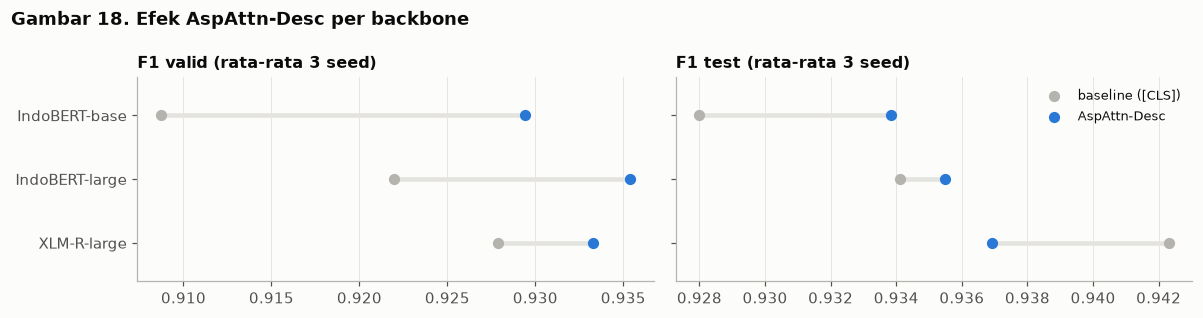

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
for ax, s in zip(axes, ["valid", "test"]):
    for i, b in enumerate(BACKBONES[::-1]):
        a, c = sig.loc[b, f"{s} baseline"], sig.loc[b, f"{s} AspAttn-Desc"]
        ax.plot([a, c], [i, i], color=GRID, lw=3, zorder=1)
        ax.scatter(a, i, color=MUTED, s=40, zorder=3, label="baseline ([CLS])" if i == 0 else None)
        ax.scatter(c, i, color=BLUE, s=40, zorder=3, label="AspAttn-Desc" if i == 0 else None)
    ax.set_yticks(range(len(BACKBONES)), BACKBONES[::-1])
    ax.set_title(f"F1 {s} (rata-rata 3 seed)", fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.6, len(BACKBONES) - 0.4)
axes[1].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Gambar 18. Efek AspAttn-Desc per backbone", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "18_aspattn_desc.png")
plt.show()

Pada valid, AspAttn-Desc selalu lebih baik, tetapi selisihnya mengecil seiring menguatnya backbone, dari +2,1 poin pada IndoBERT-base menjadi +0,5 poin pada XLM-R-large. Pada test, kenaikan hanya signifikan untuk IndoBERT-base (+1,16 poin, interval 95% +0,14 sampai +2,22). Pada IndoBERT-large selisihnya +0,87 dan pada XLM-R-large −0,24, keduanya tidak signifikan. Deskripsi aspek membantu model base yang kapasitasnya terbatas, sedangkan model large tampaknya mampu mempelajari batas aspek sendiri. Dengan AspAttn-Desc, IndoBERT-base (124 juta parameter) menyamai IndoBERT-large baseline (335 juta parameter) di test.

### 5.4 Pengaruh AspAttn-Desc terhadap kesalahan sistematis

In [22]:
rows = {}
for m in ["IndoBERT-base", "IndoBERT-base + AspAttn-Desc", "IndoBERT-large", "IndoBERT-large + AspAttn-Desc",
          "XLM-R-large", "XLM-R-large + AspAttn-Desc"]:
    p = pred(m, "test")
    fixed = {k: int(sum(p[i, ASPECTS.index(a)] == Y["test"][i, ASPECTS.index(a)] for i, a in zip(g.i, g.aspek)))
             for k, g in ann.groupby("kategori", sort=False)}
    rows[m] = {**{f"diperbaiki: {k}": v for k, v in fixed.items()}, "total sel salah": int((p != Y["test"]).sum()),
               **error_types(Y["test"], p)}
pd.DataFrame(rows).T

,diperbaiki: label noise,diperbaiki: batas aspek,diperbaiki: aspek implisit,diperbaiki: kesalahan model,total sel salah,miss,false alarm,flip
IndoBERT-base,0,0,0,0,88,40,34,14
IndoBERT-base + AspAttn-Desc,3,1,0,1,78,36,33,9
IndoBERT-large,0,0,0,0,88,43,32,13
IndoBERT-large + AspAttn-Desc,1,3,1,1,82,34,37,11
XLM-R-large,0,0,0,0,73,24,40,9
XLM-R-large + AspAttn-Desc,0,1,1,0,76,29,38,9


AspAttn-Desc hanya memperbaiki 2–6 dari 46 sel sistematis, dan perbaikannya tersebar di semua kategori. Penurunan kesalahan IndoBERT-base dari 88 menjadi 78 sel terutama berasal dari kesalahan acak. Kesalahan sistematis sebagian besar berasal dari label, sehingga tidak dapat diselesaikan dengan model yang lebih baik.

### 5.5 Eksplorasi metode lain

Sembilan metode lain juga diuji dengan protokol yang sama melalui `scripts/explore.py`.

| Kelompok | Varian | Ide | Pembanding |
|---|---|---|---|
| Formulasi | PAIR (*auxiliary sentence*) | ulasan dipasangkan dengan pertanyaan "bagaimana {aspek}?" | IndoBERT-base |
| Regularisasi | R-Drop | dua *forward pass* dengan dropout berbeda dan penalti KL | IndoBERT-base |
| Augmentasi | ConcatAug | dua ulasan dengan aspek berbeda digabung menjadi satu contoh | IndoBERT-base |
| Adaptasi domain | TAPT | MLM pada teks train sebelum fine-tuning | IndoBERT-base |
| Pembersihan label | *Confident learning* | sel yang labelnya tidak dipercaya model diabaikan pada loss | IndoBERT-base |
| Preprocessing | `text_norm` | normalisasi slang dipakai juga untuk transformer | XLM-R-base |
| Backbone | mDeBERTa-v3-base | encoder multibahasa yang lebih baru | XLM-R-base |
| Backbone | IndoLEM IndoBERT-base | IndoBERT versi lain | IndoBERT-base |
| Backbone | IndoBERT-large-p1 | checkpoint fase 1 | IndoBERT-large |

In [23]:
sys.path.insert(0, str(ROOT / "scripts"))
import explore

show_code(explore.question, explore.PairModel)
print(tok(DATA["test"].text_clean[DEMO], explore.question("linen")).tokens()[-8:])   # ujung input pasangan: [SEP] pertanyaan [SEP]

```python
def question(a):
    return f"bagaimana {ASPECT_TEXT[a]}?"


class PairModel(nn.Module):
    """Formulasi auxiliary sentence (Sun et al., 2019): input (ulasan, pertanyaan aspek) -> 4 kelas untuk satu aspek."""

    def __init__(self, name):
        from transformers import AutoModel
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.drop = nn.Dropout(0.1)
        self.out = nn.Linear(self.enc.config.hidden_size, N_CLS)

    def forward(self, input_ids, attention_mask):
        h = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.out(self.drop(h)).view(-1, 1, N_CLS)
```

['dipenuhi', '.', '[SEP]', 'bagaimana', 'line', '##n', '?', '[SEP]']


In [24]:
EXPLORE = [("IndoBERT-base PAIR", "IndoBERT-base"), ("IndoBERT-base + R-Drop", "IndoBERT-base"),
           ("IndoBERT-base + ConcatAug", "IndoBERT-base"), ("IndoBERT-base + TAPT", "IndoBERT-base"),
           ("IndoBERT-base + CL-clean", "IndoBERT-base"), ("XLM-R-base (text_norm)", "XLM-R-base"),
           ("mDeBERTa-v3-base", "XLM-R-base"), ("IndoLEM-IndoBERT-base", "IndoBERT-base"),
           ("IndoBERT-large-p1", "IndoBERT-large"), ("IndoBERT-base + AspAttn-Desc", "IndoBERT-base")]
rows = []
for m, ref in EXPLORE:
    rs = [r for r in RUNS + XRUNS if r["name"] == m]
    rows.append({"varian": m, "pembanding": ref, "valid pembanding": seed_mean(ref, "valid"), "valid": seed_mean(m, "valid"),
                 "test pembanding": seed_mean(ref, "test"), "test": seed_mean(m, "test"),
                 **paired_bootstrap(pred(ref, "test"), pred(m, "test")),
                 "menit/seed": np.mean([r["minutes"] for r in rs])})
xp = pd.DataFrame(rows).set_index("varian")
xp.style.format({c: "{:.4f}" for c in xp.columns[1:5]} | {c: "{:+.2f}" for c in xp.columns[5:8]}
                | {"p (Δ ≤ 0)": "{:.3f}", "menit/seed": "{:.1f}"})

,pembanding,valid pembanding,valid,test pembanding,test,Δ F1 (poin),CI 95% bawah,CI 95% atas,p (Δ ≤ 0),menit/seed
varian,,,,,,,,,,
IndoBERT-base PAIR,IndoBERT-base,0.9087,0.9264,0.9280,0.9334,+1.43,+0.33,+2.55,0.004,13.1
IndoBERT-base + R-Drop,IndoBERT-base,0.9087,0.9085,0.9280,0.9266,+0.13,-0.53,+0.84,0.341,4.0
IndoBERT-base + ConcatAug,IndoBERT-base,0.9087,0.9195,0.9280,0.9271,+0.25,-0.95,+1.62,0.349,4.7
IndoBERT-base + TAPT,IndoBERT-base,0.9087,0.9145,0.9280,0.9266,+0.05,-1.05,+1.21,0.460,3.0
IndoBERT-base + CL-clean,IndoBERT-base,0.9087,0.8989,0.9280,0.9197,-0.27,-1.39,+0.90,0.664,2.5
XLM-R-base (text_norm),XLM-R-base,0.8914,0.8779,0.9127,0.8943,-2.77,-4.38,-1.36,1.000,4.8
mDeBERTa-v3-base,XLM-R-base,0.8914,0.8787,0.9127,0.8919,-1.86,-3.42,-0.42,0.993,7.6
IndoLEM-IndoBERT-base,IndoBERT-base,0.9087,0.8864,0.9280,0.9031,-2.06,-3.51,-0.61,1.000,2.6
IndoBERT-large-p1,IndoBERT-large,0.9220,0.9240,0.9341,0.9335,+0.80,+0.19,+1.56,0.003,7.5


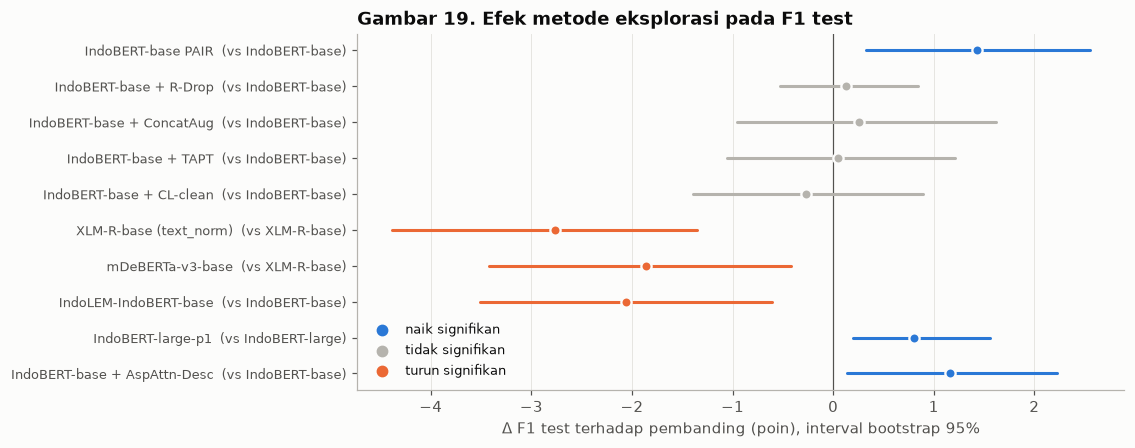

In [25]:
d = xp.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (m, r) in enumerate(d.iterrows()):
    sig_up, sig_down = r["CI 95% bawah"] > 0, r["CI 95% atas"] < 0
    c = BLUE if sig_up else ORANGE if sig_down else MUTED
    ax.plot([r["CI 95% bawah"], r["CI 95% atas"]], [i, i], color=c, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter(r["Δ F1 (poin)"], i, color=c, s=45, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(0, color=INK_2, lw=0.8, zorder=1)
ax.set_yticks(range(len(d)), [f"{m}  (vs {r['pembanding']})" for m, r in d.iterrows()], fontsize=8.5)
ax.set_xlabel("Δ F1 test terhadap pembanding (poin), interval bootstrap 95%")
ax.grid(axis="y", visible=False)
for lab, c in [("naik signifikan", BLUE), ("tidak signifikan", MUTED), ("turun signifikan", ORANGE)]:
    ax.scatter([], [], color=c, s=45, label=lab)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Gambar 19. Efek metode eksplorasi pada F1 test", x=0, ha="left")
fig.savefig(FIG_DIR / "19_eksplorasi.png")
plt.show()

PAIR merupakan satu-satunya metode tambahan yang naik signifikan (+1,43 poin test). Hasilnya setara dengan AspAttn-Desc (test 0,933 dan 0,934) dan selisih keduanya tidak signifikan, tetapi pelatihannya sekitar enam kali lebih lambat (13,1 berbanding 2,2 menit per seed) karena membutuhkan sepuluh *forward pass* per ulasan.

ConcatAug dan TAPT menaikkan valid tetapi tidak test, dan R-Drop tidak berpengaruh. *Confident learning* menurunkan skor, karena sel yang dibuangnya sebagian besar merupakan konvensi anotator yang juga muncul di test. Normalisasi slang merugikan transformer (−2,77 poin), karena tokenizer subword sudah menangani variasi ejaan. Ketiga backbone lain tidak lebih baik daripada pembandingnya pada rata-rata per seed. Selisih bootstrap IndoBERT-large-p1 yang positif (+0,80) muncul karena probabilitas rata-rata tiga seed p2 kebetulan lemah di test (0,930).

In [26]:
display(pd.DataFrame({"PAIR vs AspAttn-Desc (IndoBERT-base)": paired_bootstrap(pred("IndoBERT-base + AspAttn-Desc", "test"),
                                                                                 pred("IndoBERT-base PAIR", "test"))}).T.round(3))

# apakah aturan pemilihan model akhir (top-2 valid, bagian 6) berubah jika semua model eksplorasi ikut kandidat?
pool = TRANSFORMERS + ["mBERT-base"] + [b + " + AspAttn-Desc" for b in BACKBONES] + [m for m, _ in EXPLORE[:-1]]
rank_all = pd.Series({m: f1_indonlu(Y["valid"], pred(m, "valid")) for m in pool}).sort_values(ascending=False)
rank_all.head(5).to_frame("F1 valid (rata-rata probabilitas 3 seed)").round(4)

,Δ F1 (poin),CI 95% bawah,CI 95% atas,p (Δ ≤ 0)
PAIR vs AspAttn-Desc (IndoBERT-base),0.272,-0.42,1.058,0.241


,F1 valid (rata-rata probabilitas 3 seed)
IndoBERT-large + AspAttn-Desc,0.9405
XLM-R-large + AspAttn-Desc,0.9384
IndoBERT-base PAIR,0.9371
IndoBERT-base + AspAttn-Desc,0.9292
IndoBERT-large-p1,0.9290


Jika model eksplorasi ikut menjadi kandidat, PAIR berada di peringkat ketiga menurut valid, sehingga dua model teratas dan model akhir tidak berubah.

## 6. Model Akhir

Aturan pemilihan ditetapkan sebelum test dilihat. Dari semua transformer yang dilatih, dipilih dua model dengan F1 valid tertinggi, lalu probabilitas keduanya dirata-ratakan. Model tunggal teratas dan ensemble tiga model ditampilkan sebagai pembanding.

In [27]:
CANDS = TRANSFORMERS + ["mBERT-base"] + [b + " + AspAttn-Desc" for b in BACKBONES]
rank = pd.Series({m: f1_indonlu(Y["valid"], pred(m, "valid")) for m in CANDS}).sort_values(ascending=False)
display(rank.to_frame("F1 valid (rata-rata probabilitas 3 seed)").round(4))

final_rows, ENS = [], {}
for k in [1, 2, 3]:
    ms = list(rank.index[:k])
    pv, pt = np.mean([probs(m, "valid") for m in ms], 0), np.mean([probs(m, "test") for m in ms], 0)
    ENS[k] = pt.argmax(-1)
    final_rows.append({"model": f"top-{k}: " + " + ".join(ms), "F1 valid": f1_indonlu(Y["valid"], pv.argmax(-1)),
                       **{f"{key} test": v for key, v in metrics(Y["test"], pt.argmax(-1)).items()}})
final = pd.DataFrame(final_rows).set_index("model")
display(final.style.format("{:.4f}"))
FINAL = ENS[2]

,F1 valid (rata-rata probabilitas 3 seed)
IndoBERT-large + AspAttn-Desc,0.9405
XLM-R-large + AspAttn-Desc,0.9384
IndoBERT-base + AspAttn-Desc,0.9292
XLM-R-large,0.9274
IndoBERT-large,0.9228
IndoBERT-base,0.9100
IndoBERTweet-base,0.8988
XLM-R-base,0.8918
mBERT-base,0.8837


,F1 valid,f1_indonlu test,f1_pair test,acc test,exact test
model,,,,,
top-1: IndoBERT-large + AspAttn-Desc,0.9405,0.9391,0.9175,0.9713,0.7727
top-2: IndoBERT-large + AspAttn-Desc + XLM-R-large + AspAttn-Desc,0.9403,0.9498,0.9325,0.9762,0.8077
top-3: IndoBERT-large + AspAttn-Desc + XLM-R-large + AspAttn-Desc + IndoBERT-base + AspAttn-Desc,0.9389,0.9480,0.9297,0.9748,0.7902


In [28]:
cmp = pd.DataFrame({f"vs {m}": paired_bootstrap(pred(m, "test"), FINAL) for m in ["XLM-R-large", "IndoBERT-large"]}).T
display(cmp.style.format({"Δ F1 (poin)": "{:+.2f}", "CI 95% bawah": "{:+.2f}", "CI 95% atas": "{:+.2f}", "p (Δ ≤ 0)": "{:.3f}"}))

summary = pd.DataFrame({
    "F1 test": {"IndoNLU paper, XLM-R-large (Wilie et al., 2020)": 0.9427,
                "XLM-R-large (rata-rata F1 per seed, notebook 2)": seed_mean("XLM-R-large", "test"),
                "XLM-R-large (rata-rata probabilitas 3 seed)": f1_indonlu(Y["test"], pred("XLM-R-large", "test")),
                "Model akhir: ensemble top-2 valid": f1_indonlu(Y["test"], FINAL),
                "Plafon kasar (label noise test dianggap benar, bagian 3)": f1_indonlu(y_fix, p_best)}})
summary.round(4)

,Δ F1 (poin),CI 95% bawah,CI 95% atas,p (Δ ≤ 0)
vs XLM-R-large,+0.43,-0.42,+1.31,0.167
vs IndoBERT-large,+1.94,+0.78,+3.17,0.001


,F1 test
"IndoNLU paper, XLM-R-large (Wilie et al., 2020)",0.9427
"XLM-R-large (rata-rata F1 per seed, notebook 2)",0.9423
XLM-R-large (rata-rata probabilitas 3 seed),0.9454
Model akhir: ensemble top-2 valid,0.9498
"Plafon kasar (label noise test dianggap benar, bagian 3)",0.9631


Dua model teratas menurut valid adalah IndoBERT-large + AspAttn-Desc (0,9405) dan XLM-R-large + AspAttn-Desc (0,9384). Ensemble keduanya mencapai **F1 test 0,9498** dan exact match 0,808, di atas angka terbaik paper IndoNLU (0,9427). Terhadap XLM-R-large saja, kenaikannya +0,43 poin dan tidak signifikan, sehingga model akhir lebih tepat disebut setara atau sedikit lebih baik. Terhadap IndoBERT-large baseline, kenaikannya signifikan (+1,94 poin). Ensemble bermanfaat karena kedua anggotanya membuat kesalahan yang berbeda.

### 6.1 Contoh prediksi model akhir pada test

Tiga contoh pertama adalah ulasan campuran yang diprediksi benar seluruhnya, sedangkan dua contoh terakhir masih salah. Notasi `aspek+` berarti positif, `aspek-` berarti negatif, dan aspek yang tidak ditulis berarti tidak dibahas.

In [29]:
def as_text(row):
    return ", ".join(f"{a}{'+' if c == 2 else '-'}" for a, c in zip(ASPECTS, row) if c != 1) or "(tidak ada)"


n_asp = (Y["test"] != 1).sum(1)
mixed = [(Y["test"][i] == 0).any() and (Y["test"][i] == 2).any() for i in range(len(Y["test"]))]
n_words = DATA["test"].review.str.split().str.len()
benar = [i for i in range(len(Y["test"])) if mixed[i] and n_asp[i] >= 3 and (FINAL[i] == Y["test"][i]).all() and n_words[i] <= 35][:3]
salah = [i for i in [275, 80, 209] if (FINAL[i] != Y["test"][i]).any()][:2]
contoh = pd.DataFrame([{"i": i, "ulasan": DATA["test"].review[i], "label emas": as_text(Y["test"][i]),
                        "prediksi model akhir": as_text(FINAL[i]), "benar semua": bool((FINAL[i] == Y["test"][i]).all()),
                        "kategori kesalahan (bagian 3)": ", ".join(ann[ann.i == i].kategori.unique()) or "–"}
                       for i in benar + salah]).set_index("i")
contoh

,ulasan,label emas,prediksi model akhir,benar semua,kategori kesalahan (bagian 3)
i,,,,,
17,"Secara keseluruhan baik, tapi sedikit catatan untuk kamar mandinya bau, banyak semacam lalet kecil, gak ada air panas.","air_panas-, bau-, general+","air_panas-, bau-, general+",True,–
18,Perlengkapan mandinya lengkap dan ac nya dingin. Hanya saja koneksi internet kurang bagus.,"ac+, linen+, wifi-","ac+, linen+, wifi-",True,–
31,Pelayanan ramah.lokasi bagus.kamar mandi tidak ada air panas. kamar kurang bersih.makasih.,"air_panas-, kebersihan-, service+","air_panas-, kebersihan-, service+",True,–
275,"Kamarnya bagus, tapi servicenya jelek banget, tidak dapat handuk, sabun tidak ada, tidak ada kotak sampahnya juga, air minum juga tidak dapat.",linen-,"linen-, service-",False,label noise
80,"Hotel yang bersahabat dengan NYAMUK, makanan selalu HABIS","kebersihan-, sunrise_meal-",sunrise_meal-,False,kesalahan model


Ketiga ulasan campuran diprediksi benar, termasuk konvensi anotator seperti *perlengkapan mandi* yang dihitung sebagai `linen`. Ulasan 275 termasuk label noise, karena teksnya menyebut "servicenya jelek banget" tetapi label emasnya `neut`. Ulasan 80 merupakan kesalahan model, karena sarkasme "bersahabat dengan NYAMUK" tidak dikenali sebagai keluhan kebersihan.

### 6.2 Demo pada ulasan baru

Untuk demo, kedua anggota model akhir dilatih ulang satu kali (seed 42) dan bobotnya disimpan di `outputs/models/` oleh `scripts/save_final.py`. Fungsi `prediksi` menjalankan alur yang sama dengan evaluasi, yaitu pembersihan teks, tokenisasi (maksimum 128 subword), kedua model, rata-rata probabilitas, lalu label per aspek.

In [30]:
from transformers import AutoConfig

from hoasa import preprocess as P
from hoasa.train import fold

MODEL_DIR = ROOT / "outputs" / "models"
ANGGOTA = ["IndoBERT-large + AspAttn-Desc", "XLM-R-large + AspAttn-Desc"]
# Bobot kedua model sekitar 3,4 GB, jadi GPU kecil dilewati agar inferensi tidak tumpah ke RAM.
DEV = "cuda" if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 8e9 else "cpu"
TERSEDIA = all((MODEL_DIR / slug(m) / "model.pt").exists() for m in ANGGOTA)
FINAL_MODELS = {}
if not TERSEDIA:
    print("Bobot model akhir belum ada. Jalankan:  HOASA_COOLDOWN=60 uv run python scripts/save_final.py")
else:
    for m in ANGGOTA:
        cfg = json.loads((MODEL_DIR / slug(m) / "config.json").read_text())
        d = AutoConfig.from_pretrained(cfg["backbone"]).hidden_size
        mdl = TransformerAspect(cfg["backbone"], query_init=torch.zeros(len(ASPECTS), d))
        mdl.load_state_dict(torch.load(MODEL_DIR / slug(m) / "model.pt", map_location="cpu"))
        FINAL_MODELS[m] = (mdl.to(DEV).eval(), AutoTokenizer.from_pretrained(cfg["backbone"]))
        print(f"{m}: epoch terbaik {cfg['best_epoch']} (seed {cfg['seed']})")


@torch.no_grad()
def prob_semua(texts, bs=64):
    """Probabilitas 3 kelas (n, 10, 3), rata-rata kedua anggota model akhir."""
    out = []
    for mdl, tk in FINAL_MODELS.values():
        ps = []
        for i in range(0, len(texts), bs):
            enc = tk([P.clean(t) for t in texts[i:i + bs]], max_length=128, truncation=True, padding=True, return_tensors="pt").to(DEV)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEV == "cuda"):
                ps.append(mdl(enc["input_ids"], enc["attention_mask"]).float().softmax(-1).cpu().numpy())
        out.append(fold(np.concatenate(ps)))
    return np.mean(out, 0)


def prediksi(teks):
    p = prob_semua([teks])[0]
    rows = [{"aspek": a, "prediksi": CL[p[j].argmax()].replace("neut", "tidak dibahas"), "keyakinan": round(float(p[j].max()), 3)}
            for j, a in enumerate(ASPECTS)]
    return pd.DataFrame(rows).set_index("aspek")


if TERSEDIA:
    p_demo = prob_semua(DATA["test"].review.tolist()).argmax(-1)
    print(f"Versi demo (1 seed per anggota) pada test: F1 {f1_indonlu(Y['test'], p_demo):.4f} | "
          f"exact match {(p_demo == Y['test']).all(1).mean():.4f}  (model akhir resmi, 3 seed: {f1_indonlu(Y['test'], FINAL):.4f})")

IndoBERT-large + AspAttn-Desc: epoch terbaik 8 (seed 42)


XLM-R-large + AspAttn-Desc: epoch terbaik 11 (seed 42)


Versi demo (1 seed per anggota) pada test: F1 0.9475 | exact match 0.8007  (model akhir resmi, 3 seed: 0.9498)


In [31]:
ULASAN_BARU = [
    "kamarnya bersih dan wangi, tapi acnya ga dingin sama sekali. wifi juga lemot bgt",
    "resepsionis ramah, sarapannya enak dan bervariasi. overall puas nginep di sini",
    "handuk tidak disediakan, snack dan air minum juga tidak ada",
    "air panasnya mati, tv cuma dapet 3 channel. kamar mandi bau",
]
if TERSEDIA:
    hasil = pd.DataFrame({t: prediksi(t).apply(lambda r: "–" if r.prediksi == "tidak dibahas" else f"{r.prediksi} ({r.keyakinan:.2f})", axis=1)
                          for t in ULASAN_BARU}).T
    hasil.index = [f"({k + 1}) {t}" for k, t in enumerate(ULASAN_BARU)]
    display(hasil)

aspek,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
"(1) kamarnya bersih dan wangi, tapi acnya ga dingin sama sekali. wifi juga lemot bgt",neg (0.98),–,pos (1.00),–,pos (1.00),–,–,–,–,neg (1.00)
"(2) resepsionis ramah, sarapannya enak dan bervariasi. overall puas nginep di sini",–,–,–,pos (1.00),–,–,pos (1.00),pos (1.00),–,–
"(3) handuk tidak disediakan, snack dan air minum juga tidak ada",–,–,–,–,–,neg (1.00),–,–,–,–
"(4) air panasnya mati, tv cuma dapet 3 channel. kamar mandi bau",–,neg (1.00),neg (1.00),–,–,–,–,–,neg (1.00),–


Versi demo mencapai F1 test 0,9475, sedikit di bawah model resmi tiga seed (0,9498). Pada ulasan (1), empat aspek dengan polaritas campuran dipisahkan dengan benar, termasuk `ac-` dari negasi informal *ga dingin*. Ulasan (2) menghasilkan `service` dari *resepsionis ramah* meskipun kata *pelayanan* tidak muncul. Ulasan (3) dan (4) mengikuti konvensi anotator, yaitu *handuk, snack,* dan *air minum* sebagai `linen`, serta *kamar mandi bau* sebagai `bau`. Ulasan lain dapat dicoba dengan `prediksi("teks ulasan")`.

In [32]:
if TERSEDIA:
    display(prediksi("lokasinya strategis, tapi kasurnya keras dan seprainya kotor"))

,prediksi,keyakinan
aspek,,
ac,tidak dibahas,1.000
air_panas,tidak dibahas,1.000
bau,tidak dibahas,1.000
general,tidak dibahas,1.000
kebersihan,tidak dibahas,0.992
linen,neg,1.000
service,tidak dibahas,1.000
sunrise_meal,tidak dibahas,1.000
tv,tidak dibahas,1.000


### 6.3 Attention per aspek setelah pelatihan

Gambar berikut menampilkan token yang dibaca IndoBERT-large + AspAttn-Desc untuk setiap aspek pada ulasan (1).

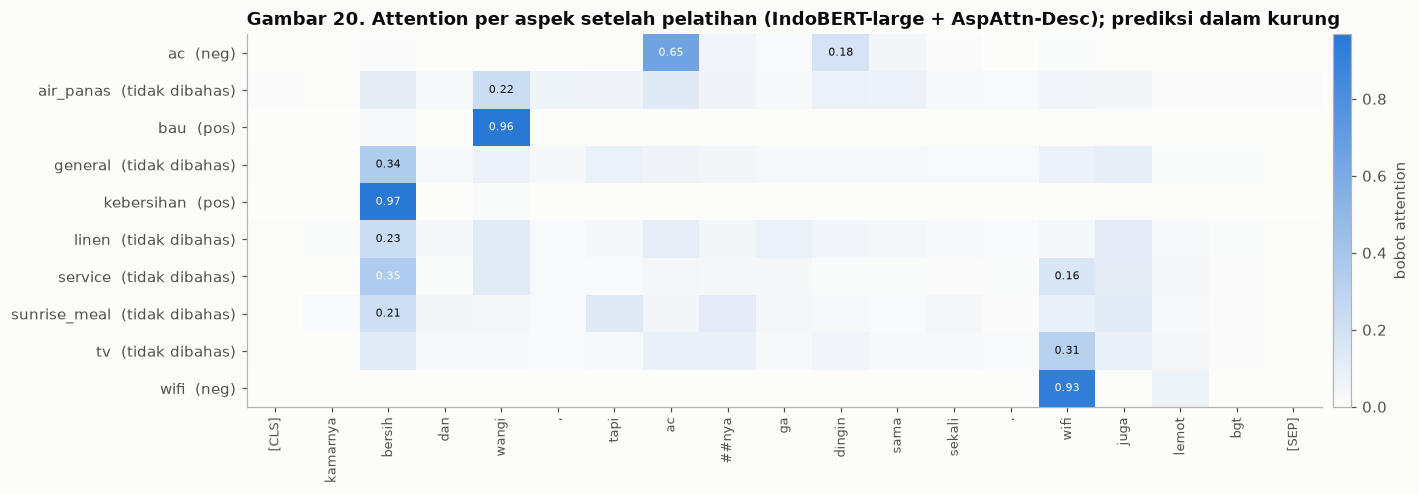

In [33]:
if TERSEDIA:
    mdl, tk = FINAL_MODELS["IndoBERT-large + AspAttn-Desc"]
    teks = ULASAN_BARU[0]
    enc = tk(P.clean(teks), return_tensors="pt").to(DEV)
    with torch.no_grad():
        h = mdl.enc(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state.float()
        att_tr = torch.einsum("btd,ad->bat", h, mdl.query.float()).div(h.shape[-1] ** 0.5).softmax(-1)[0].cpu().numpy()
    toks = tk.convert_ids_to_tokens(enc["input_ids"][0])
    pr = prediksi(teks).prediksi
    fig, ax = plt.subplots(figsize=(13, 4.4))
    im = ax.imshow(att_tr, aspect="auto", cmap=LinearSegmentedColormap.from_list("biru", [SURFACE, BLUE]), vmin=0, vmax=att_tr.max())
    ax.set_xticks(range(len(toks)), toks, rotation=90, fontsize=8.5)
    ax.set_yticks(range(len(ASPECTS)), [f"{a}  ({pr[a]})" for a in ASPECTS])
    ax.grid(False)
    for i, j in zip(*np.where(att_tr >= 0.15)):
        ax.text(j, i, f"{att_tr[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=SURFACE if att_tr[i, j] > 0.35 else INK)
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="bobot attention")
    ax.set_title("Gambar 20. Attention per aspek setelah pelatihan (IndoBERT-large + AspAttn-Desc); prediksi dalam kurung")
    fig.savefig(FIG_DIR / "20_attention_terlatih.png")
    plt.show()

Setelah pelatihan, attention setiap aspek terpusat pada kata aspeknya sendiri, misalnya `kebersihan` pada *bersih* (0,97) dan `wifi` pada *wifi* (0,93). Pemisahannya jauh lebih jelas dibandingkan Gambar 17. Attention `wifi` tidak jatuh pada *lemot*, tetapi prediksinya tetap `neg`, karena vektor token *wifi* sudah memuat konteks di sekitarnya melalui self-attention. Aspek yang tidak dibahas hanya memiliki puncak yang jauh lebih rendah dan diprediksi tidak dibahas.

## 7. Kesimpulan

Kesalahan transformer didominasi oleh deteksi aspek, terutama pada aspek `general`, `kebersihan`, dan `linen`, serta pada ulasan panjang dengan banyak aspek. Sekitar dua pertiga kesalahan model terbaik bersifat sistematis, dan sebagian besar di antaranya berasal dari label noise dan konvensi anotasi yang tidak konsisten. Label noise di test saja menekan F1 sekitar 1,8 poin.

Mitigasi yang dipakai adalah perata-rataan seed, ensemble dua model terbaik menurut valid, dan AspAttn-Desc, yang signifikan pada IndoBERT-base. Bias ambang, label smoothing, dan metode eksplorasi lain tidak meningkatkan hasil di test. Model akhir mencapai **F1 test 0,9498**.

Keterbatasannya adalah sebagai berikut.
- Kategori kesalahan ditetapkan secara manual oleh satu orang.
- Test hanya berisi 286 ulasan, sehingga selisih di bawah sekitar 1 poin umumnya tidak signifikan.
- Hiperparameter AspAttn-Desc tidak dituning, karena tuning tambahan berisiko overfit pada valid yang kecil.